# Subquestion 3: overall crash risk vs. injury and fatal crash risk

In [1]:
import pandas as pd

df = pd.read_csv("cleaned_data/05_analysis_ready_zh_motorways.csv")

print(df.shape)
df.head()

(1228, 28)


,VBN_ID,ROAD_DESCRIPTION,ROAD_NUMBER,ROAD_LENGTH_M,DIRECTION_BEGIN,DIRECTION_END,CARRIAGEWAY_TYPE_BEGIN,CARRIAGEWAY_TYPE_END,HAS_TRAFFIC_DATA,AVG_DAILY_TRAFFIC,...,TRAFFIC_COVERAGE_PCT,ANNUAL_VEHICLE_KM,TOTAL_CRASHES,MATERIAL_DAMAGE_CRASHES,INJURY_CRASHES,FATAL_CRASHES,INJURY_FATAL_CRASHES,CRASH_RATE_PER_100M_VKM,INJURY_FATAL_RATE_PER_100M_VKM,GEOMETRY_WKT
0,10000000001492700860,A15 b (OPR) Havens 5500-5600,A15,45.0,Re,Re,OPR,OPR,1,250.0,...,100.0,4106.25,0,0,0,0,0,0.000000,0.0,"LINESTRING (74567.64199 435285.76651, 74568.62..."
1,10000000001512701040,A15 b (OPR) Rozenburg,A15,97.0,Re,Re,OPR,OPR,1,3100.0,...,100.0,109755.50,0,0,0,0,0,0.000000,0.0,"LINESTRING (75525.972 435244.552, 75528.06123 ..."
2,10000000001512701050,A15 d (OPR) ROZENBURG,A15,140.0,Li,Li,OPR,OPR,1,2800.0,...,100.0,143080.00,0,0,0,0,0,0.000000,0.0,"LINESTRING (75723.8393445015 435362.893433999,..."
3,10000000001512810410,A20 b (OPR) Maasdijk-Oost,A20,378.0,Re,Re,OPR,OPR,1,6100.0,...,100.0,841617.00,1,1,0,0,0,118.818893,0.0,"LINESTRING (75556.498 441053.268, 75575.046100..."
4,10000000001512820560,A20 d (OPR) Maasdijk-Oost,A20,377.0,Li,Li,OPR,OPR,1,3900.0,...,100.0,536659.50,0,0,0,0,0,0.000000,0.0,"LINESTRING (75658.233 441162.014, 75654.673099..."


In [2]:
cols = [
    "TOTAL_CRASHES",
    "INJURY_CRASHES",
    "FATAL_CRASHES",
    "INJURY_FATAL_CRASHES",
    "ANNUAL_VEHICLE_KM"
]

df[cols].describe()

,TOTAL_CRASHES,INJURY_CRASHES,FATAL_CRASHES,INJURY_FATAL_CRASHES,ANNUAL_VEHICLE_KM
count,1228.000000,1228.000000,1228.000000,1228.000000,1.223000e+03
mean,5.938925,0.575733,0.008958,0.584691,9.667162e+06
std,13.136808,1.598175,0.094258,1.604850,1.826742e+07
min,0.000000,0.000000,0.000000,0.000000,2.861600e+03
25%,0.000000,0.000000,0.000000,0.000000,7.273902e+05
50%,1.000000,0.000000,0.000000,0.000000,2.656288e+06
75%,5.000000,0.000000,0.000000,0.000000,1.073615e+07
max,159.000000,24.000000,1.000000,24.000000,1.888850e+08


In [3]:
df["CRASH_RATE_PER_M_VKM"] = (
    df["TOTAL_CRASHES"]
    / df["ANNUAL_VEHICLE_KM"]
    * 1_000_000
)

df["INJURY_FATAL_RATE_PER_M_VKM"] = (
    df["INJURY_FATAL_CRASHES"]
    / df["ANNUAL_VEHICLE_KM"]
    * 1_000_000
)

In [4]:
MIN_VKM = 1_000_000

eligible = df[
    df["ANNUAL_VEHICLE_KM"] >= MIN_VKM
].copy()

print("Eligible sections:", len(eligible))

Eligible sections: 849


In [5]:
show = [
    "ROAD_DESCRIPTION",
    "ROAD_LENGTH_M",
    "AVG_DAILY_TRAFFIC",
    "TOTAL_CRASHES",
    "INJURY_FATAL_CRASHES",
    "CRASH_RATE_PER_M_VKM",
    "INJURY_FATAL_RATE_PER_M_VKM"
]

top_overall = (
    eligible
    .sort_values(
        "CRASH_RATE_PER_M_VKM",
        ascending=False
    )
    .head(10)
)

top_overall[show]

,ROAD_DESCRIPTION,ROAD_LENGTH_M,AVG_DAILY_TRAFFIC,TOTAL_CRASHES,INJURY_FATAL_CRASHES,CRASH_RATE_PER_M_VKM,INJURY_FATAL_RATE_PER_M_VKM
609,A20 a (AFR) Rotterdam-Noord,400.0,7700.0,10,1,8.895214,0.889521
57,A4 b (OPR) Vlaardingen-Oost,287.0,10300.0,9,1,8.341238,0.926804
87,A20 d (OPR) Rotterdam-Schiebroek,415.0,12200.0,11,2,5.952397,1.082254
600,A20 c (AFR) Knooppunt Kleinpolderplein - Kp.kl...,400.0,7000.0,6,1,5.870841,0.978474
377,A4 a (AFR) Vlaardingen-Oost,380.0,8500.0,6,0,5.089274,0.000000
749,A15 a (AFR) Rotterdam-Ijsselmonde,404.0,14200.0,10,1,4.775704,0.477570
1074,A4 c (AFR) Leiden,603.0,6200.0,6,2,4.396928,1.465643
179,A15 Re (HR) Rotterdam - oostvoorne,731.0,13700.0,15,2,4.103557,0.547141
683,A29 Re (HR) Knooppunt Vaanplein,627.0,7800.0,7,2,3.921417,1.120405
91,A20 b (OPR) Rotterdam-Noord,251.0,16800.0,6,2,3.898301,1.299434


In [6]:
top_serious = (
    eligible
    .sort_values(
        "INJURY_FATAL_RATE_PER_M_VKM",
        ascending=False
    )
    .head(10)
)

top_serious[show]

,ROAD_DESCRIPTION,ROAD_LENGTH_M,AVG_DAILY_TRAFFIC,TOTAL_CRASHES,INJURY_FATAL_CRASHES,CRASH_RATE_PER_M_VKM,INJURY_FATAL_RATE_PER_M_VKM
1074,A4 c (AFR) Leiden,603.0,6200.0,6,2,4.396928,1.465643
91,A20 b (OPR) Rotterdam-Noord,251.0,16800.0,6,2,3.898301,1.299434
683,A29 Re (HR) Knooppunt Vaanplein,627.0,7800.0,7,2,3.921417,1.120405
87,A20 d (OPR) Rotterdam-Schiebroek,415.0,12200.0,11,2,5.952397,1.082254
658,A4 m (VBR) ZOETERWOUDE,371.0,22200.0,4,3,1.330578,0.997933
600,A20 c (AFR) Knooppunt Kleinpolderplein - Kp.kl...,400.0,7000.0,6,1,5.870841,0.978474
57,A4 b (OPR) Vlaardingen-Oost,287.0,10300.0,9,1,8.341238,0.926804
609,A20 a (AFR) Rotterdam-Noord,400.0,7700.0,10,1,8.895214,0.889521
944,A15 d (OPR) Alblasserdam,389.0,8700.0,2,1,1.619080,0.809540
116,A15 b (OPR) Rotterdam-Ijsselmonde,256.0,14200.0,4,1,3.014663,0.753666


In [7]:
overlap = (
    set(top_overall["VBN_ID"])
    & set(top_serious["VBN_ID"])
)

print("Sections in both top 10s:", len(overlap))

eligible[
    eligible["VBN_ID"].isin(overlap)
][show]

Sections in both top 10s: 7


,ROAD_DESCRIPTION,ROAD_LENGTH_M,AVG_DAILY_TRAFFIC,TOTAL_CRASHES,INJURY_FATAL_CRASHES,CRASH_RATE_PER_M_VKM,INJURY_FATAL_RATE_PER_M_VKM
57,A4 b (OPR) Vlaardingen-Oost,287.0,10300.0,9,1,8.341238,0.926804
87,A20 d (OPR) Rotterdam-Schiebroek,415.0,12200.0,11,2,5.952397,1.082254
91,A20 b (OPR) Rotterdam-Noord,251.0,16800.0,6,2,3.898301,1.299434
600,A20 c (AFR) Knooppunt Kleinpolderplein - Kp.kl...,400.0,7000.0,6,1,5.870841,0.978474
609,A20 a (AFR) Rotterdam-Noord,400.0,7700.0,10,1,8.895214,0.889521
683,A29 Re (HR) Knooppunt Vaanplein,627.0,7800.0,7,2,3.921417,1.120405
1074,A4 c (AFR) Leiden,603.0,6200.0,6,2,4.396928,1.465643


In [8]:
rho = eligible[
    "CRASH_RATE_PER_M_VKM"
].corr(
    eligible["INJURY_FATAL_RATE_PER_M_VKM"],
    method="spearman"
)

print(
    f"Spearman rank correlation "
    f"(overall risk vs. injury/fatal risk): {rho:.2f}"
)

Spearman rank correlation (overall risk vs. injury/fatal risk): 0.46


In [9]:
with_serious_crashes = eligible[
    eligible["INJURY_FATAL_CRASHES"] > 0
]

rho_serious = with_serious_crashes[
    "CRASH_RATE_PER_M_VKM"
].corr(
    with_serious_crashes[
        "INJURY_FATAL_RATE_PER_M_VKM"
    ],
    method="spearman"
)

print(
    f"Spearman, only sections with >= 1 injury/fatal crash: "
    f"{rho_serious:.2f}"
)

print(
    "Sections with at least one injury/fatal crash:",
    len(with_serious_crashes)
)

Spearman, only sections with >= 1 injury/fatal crash: 0.63
Sections with at least one injury/fatal crash: 281


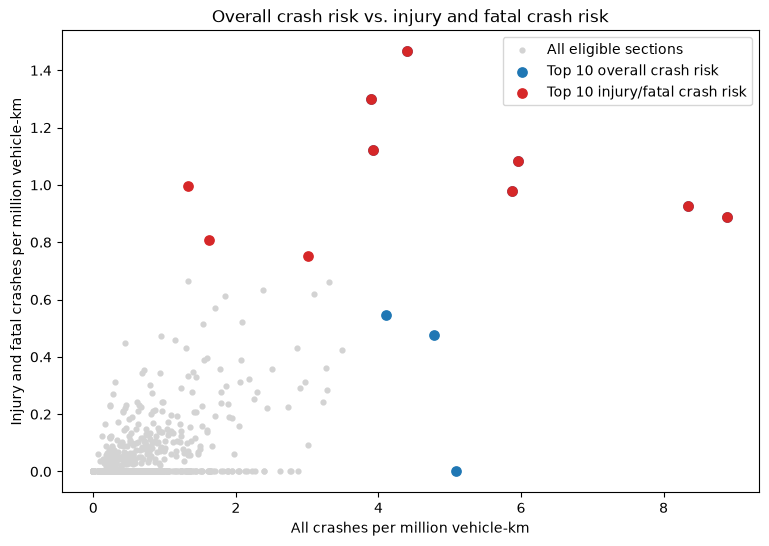

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    eligible["CRASH_RATE_PER_M_VKM"],
    eligible["INJURY_FATAL_RATE_PER_M_VKM"],
    s=12,
    color="lightgrey",
    label="All eligible sections"
)

ax.scatter(
    top_overall["CRASH_RATE_PER_M_VKM"],
    top_overall["INJURY_FATAL_RATE_PER_M_VKM"],
    s=45,
    color="tab:blue",
    label="Top 10 overall crash risk"
)

ax.scatter(
    top_serious["CRASH_RATE_PER_M_VKM"],
    top_serious["INJURY_FATAL_RATE_PER_M_VKM"],
    s=45,
    color="tab:red",
    label="Top 10 injury/fatal crash risk"
)

ax.set_xlabel(
    "All crashes per million vehicle-km"
)

ax.set_ylabel(
    "Injury and fatal crashes per million vehicle-km"
)

ax.set_title(
    "Overall crash risk vs. injury and fatal crash risk"
)

ax.legend()

plt.show()

In [11]:
eligible["OVERALL_RISK_RANK"] = (
    eligible["CRASH_RATE_PER_M_VKM"]
    .rank(
        ascending=False,
        method="min"
    )
)

eligible["SERIOUS_RISK_RANK"] = (
    eligible["INJURY_FATAL_RATE_PER_M_VKM"]
    .rank(
        ascending=False,
        method="min"
    )
)

eligible["RANK_DIFFERENCE"] = (
    eligible["OVERALL_RISK_RANK"]
    - eligible["SERIOUS_RISK_RANK"]
)

ranking_comparison = eligible[
    [
        "ROAD_DESCRIPTION",
        "TOTAL_CRASHES",
        "INJURY_FATAL_CRASHES",
        "CRASH_RATE_PER_M_VKM",
        "INJURY_FATAL_RATE_PER_M_VKM",
        "OVERALL_RISK_RANK",
        "SERIOUS_RISK_RANK",
        "RANK_DIFFERENCE"
    ]
]

ranking_comparison.sort_values(
    "SERIOUS_RISK_RANK"
).head(20)

,ROAD_DESCRIPTION,TOTAL_CRASHES,INJURY_FATAL_CRASHES,CRASH_RATE_PER_M_VKM,INJURY_FATAL_RATE_PER_M_VKM,OVERALL_RISK_RANK,SERIOUS_RISK_RANK,RANK_DIFFERENCE
1074,A4 c (AFR) Leiden,6,2,4.396928,1.465643,7.0,1.0,6.0
91,A20 b (OPR) Rotterdam-Noord,6,2,3.898301,1.299434,10.0,2.0,8.0
683,A29 Re (HR) Knooppunt Vaanplein,7,2,3.921417,1.120405,9.0,3.0,6.0
87,A20 d (OPR) Rotterdam-Schiebroek,11,2,5.952397,1.082254,3.0,4.0,-1.0
658,A4 m (VBR) ZOETERWOUDE,4,3,1.330578,0.997933,111.0,5.0,106.0
600,A20 c (AFR) Knooppunt Kleinpolderplein - Kp.kl...,6,1,5.870841,0.978474,4.0,6.0,-2.0
57,A4 b (OPR) Vlaardingen-Oost,9,1,8.341238,0.926804,2.0,7.0,-5.0
609,A20 a (AFR) Rotterdam-Noord,10,1,8.895214,0.889521,1.0,8.0,-7.0
944,A15 d (OPR) Alblasserdam,2,1,1.619080,0.809540,71.0,9.0,62.0
116,A15 b (OPR) Rotterdam-Ijsselmonde,4,1,3.014663,0.753666,17.0,10.0,7.0


## Conclusion sub-question 3

The ranking based on the overall crash rate and the ranking based on the injury/fatal crash rate largely point to the same road sections, but they are not entirely identical:
**7 out of 10 road sections appear in both top 10 lists.**

- **Based on the general crash rate**, road sections with a relatively high number of accidents in relation to the number of vehicle-kilometers traveled rank particularly high. Examples of this include the A20 a (AFR) Rotterdam-Noord, A4 b (OPR) Vlaardingen-Oost, and A20 d (OPR) Rotterdam-Schiebroek.
- **Based on the injury/fatal crash rate**, many of the same road segments appear, though some shift significantly in their ranking. For instance, the A4 (VBR) section at Zoeterwoude ranks only 111th for general crash risk, yet it ranks 5th for injury/fatal crash risk. Similarly, the A15 (OPR) section at Alblasserdam rises from 71st to 9th place. This demonstrates that a road segment with a relatively low overall crash rate can still carry a high risk of serious accidents.

Across all the road segments included, the two rankings are positively correlated (Spearman ρ = 0.46), though the agreement is not perfect. When considering only those road segments that have experienced at least one injury or fatal accident, the correlation increases to ρ = 0.63. This indicates that road segments with a high overall crash risk generally also have a higher risk of injury or fatal crashes, although there are clear exceptions.

**Method choice:** As with sub-question 1, only road segments with at least 1 million vehicle-kilometers per year have been included in the risk ranking. This prevents road segments with very low traffic volumes from having an extremely high crash rate due to a single accident.

**Limitation:** Injury and fatal accidents occur relatively infrequently. As a result, the injury/fatal crash rate for an individual road segment can be heavily influenced by just one or a few serious accidents.

**Conclusion:** The road sections with the highest risk of injury-causing or fatal accidents are largely the same as those with the highest overall accident risk, though not entirely. The 70% overlap indicates a clear correlation, while the differences in ranking demonstrate that analyzing severe accidents separately provides additional insight.